## Exercise 2.1

Load to a dataframe the file `GDP(PPP)_LifeExpectancy.xlsx` in the folder `Datasets`.
- Don't load the column Code which contains the full name of the country
- Use the following column names: 'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
- Encode invalid values to `np.nan`

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/Colab_Notebooks/

/content/drive/MyDrive/Colab_Notebooks


In [25]:
import pandas as pd
import numpy as np


df = pd.read_excel('Datasets/GDP(PPP)_LifeExpectancy.xlsx', na_values=['...', '..', 'N/A', 'NA', ''])

df_gdp = df.pivot_table(
    index='Country Name',
    columns='Series Name',
    values='2023 [YR2023]'
).reset_index()

df_gdp = df_gdp.rename(columns={
    'Country Name': 'Country',
    'GDP per capita, PPP (current international $)': 'GDP',
    'Life expectancy at birth, total (years)': 'Life_Exp'
})

df_gdp['Population'] = np.nan
df_gdp['Inc_Class'] = np.nan
df_gdp = df_gdp[['Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class']]

df_gdp.head()

Series Name,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,66.035,2201.722907,NaN,NaN
1,Albania,79.602,21259.797781,NaN,NaN
2,Algeria,76.261,16824.487903,NaN,NaN
3,American Samoa,72.852,NaN,NaN,NaN
4,Andorra,84.041,71730.668682,NaN,NaN


## Exercise 3.1

The BitCoin Year-on-Year price data in CSV format could be found in this link: https://api.blockchain.info/charts/market-price?format=csv.
1. Download a copy of the CSV file and observe its characteristics.
2. Load the file directly from the url/website and assign it to a DataFrame called `df_bitcoin`
3. Plot the data

In [20]:
import pandas as pd
import matplotlib.pyplot as plt


url = 'https://api.blockchain.info/charts/market-price?format=csv'
df_bitcoin = pd.read_csv(url, header=None, names=['Date', 'Price'])

df_bitcoin['Date'] = pd.to_datetime(df_bitcoin['Date'])
df_bitcoin.set_index('Date', inplace=True)

display(df_bitcoin.head())

,Price
Date,
2025-10-27,114531.59
2025-10-28,114121.46
2025-10-29,112923.91
2025-10-30,110068.52
2025-10-31,108303.21


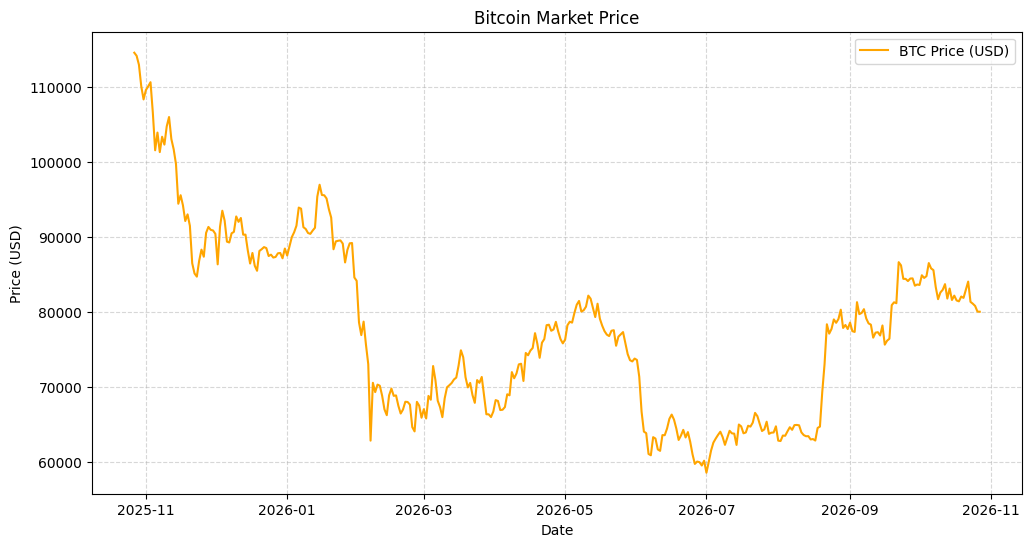

In [5]:
plt.figure(figsize=(12, 6))
plt.plot(df_bitcoin.index, df_bitcoin['Price'], label='BTC Price (USD)', color='orange')
plt.title('Bitcoin Market Price')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

## Exercise 4.1

Answer the following questions regarding the `df_gdp` you created in Exercise 2.1:
  1. What are the dimensions of the DataFrame?
  2. How many valid GDP values are there?
  3. What is the average life expectancy for all countries?
  4. Sort the dataframe by Country and assign it to a new DataFrame
  5. What are the top 5 countries with the highest GDP?
  6. What are the top 5 countries with smallest population?

In [28]:
#1. What are the dimensions of the DataFrame?
print("1. Dimensions:", df_gdp.shape)

#2. How many valid GDP values are there?
print("2. Valid GDP values:", df_gdp['GDP'].count())

#3.  What is the average life expectancy for all countries?
print("3. Average Life Expectancy:", df_gdp['Life_Exp'].mean())

#4.  Sort the dataframe by Country and assign it to a new DataFrame
print("4. Sorted DataFrame by Country assigned to df_gdp_sorted.")
df_sorted = df_gdp.sort_values('Country')
display(df_sorted)

#5. What are the top 5 countries with the highest GDP?
print("\n5. Top 5 countries with highest GDP:")
display(df_gdp.nlargest(5, 'GDP')[['Country', 'GDP']])

#6. What are the top 5 countries with smallest population?
print("\n6. Top 5 countries with smallest population:")
display(df_gdp.nsmallest(5, 'Population')[['Country', 'Population']])

1. Dimensions: (217, 5)
2. Valid GDP values: 197
3. Average Life Expectancy: 73.80012419916825
4. Sorted DataFrame by Country assigned to df_gdp_sorted.


Series Name,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,66.035000,2201.722907,NaN,NaN
1,Albania,79.602000,21259.797781,NaN,NaN
2,Algeria,76.261000,16824.487903,NaN,NaN
3,American Samoa,72.852000,NaN,NaN,NaN
4,Andorra,84.041000,71730.668682,NaN,NaN
...,...,...,...,...,...
212,Virgin Islands (U.S.),80.519512,NaN,NaN,NaN
213,West Bank and Gaza,65.170000,5950.020062,NaN,NaN
214,"Yemen, Rep.",69.295000,NaN,NaN,NaN
215,Zambia,66.349000,4076.995087,NaN,NaN



5. Top 5 countries with highest GDP:


Series Name,Country,GDP
171,Singapore,143786.136293
116,Luxembourg,142424.729887
159,Qatar,128918.549293
93,Ireland,124900.938635
117,"Macao SAR, China",116491.377162



6. Top 5 countries with smallest population:


Series Name,Country,Population
0,Afghanistan,NaN
1,Albania,NaN
2,Algeria,NaN
3,American Samoa,NaN
4,Andorra,NaN
